# Ensemble-Methode zur Klassifikation handgeschriebener Ziffern

## Arbeitsschritte:

0. Imports
1. MNIST Dataset
2. Datenvorbereitung
3. Modelle
4. Ensemble
5. Evaluation


# 0. Imports

In [5]:
# --- Standard library ---

import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf                          
import tensorflow.keras as keras


from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report


# 1. MNIST Dataset

## 1.1 Daten laden

In [6]:
### load dataset
mnist = tf.keras.datasets.mnist
(X_train, y_train), (X_test, y_test) = mnist.load_data()

# Daten normalisieren
X_train = X_train / 255.0
X_test = X_test / 255.0

# Flatten (wichtig für sklearn Modelle)
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)


## 1.2 Klassenverteilung

=== Klassenverteilung ===
0    5923
1    6742
2    5958
3    6131
4    5842
5    5421
6    5918
7    6265
8    5851
9    5949
Name: count, dtype: int64


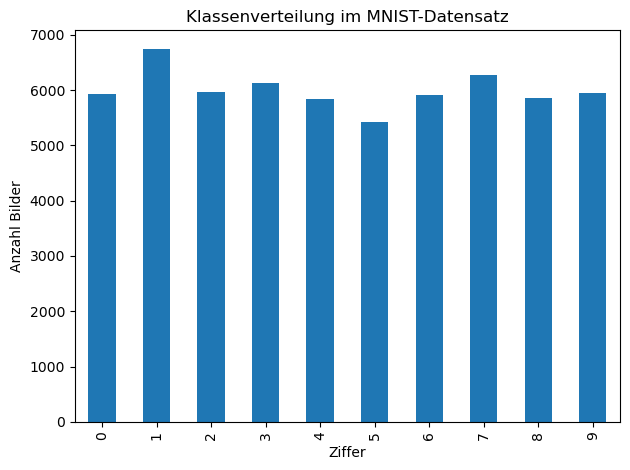

In [3]:
# Klassenverteilung

y_series = pd.Series(y_train)

class_counts = y_series.value_counts().sort_index()

print("=== Klassenverteilung ===")
print(class_counts)

plt.figure()
class_counts.plot(kind='bar')

plt.title("Klassenverteilung im MNIST-Datensatz")
plt.xlabel("Ziffer")
plt.ylabel("Anzahl Bilder")

plt.tight_layout()
plt.savefig("figures/klassenverteilung_mnist.png", dpi=300)
plt.show()

## 1.3 Visualisierung der Bilder

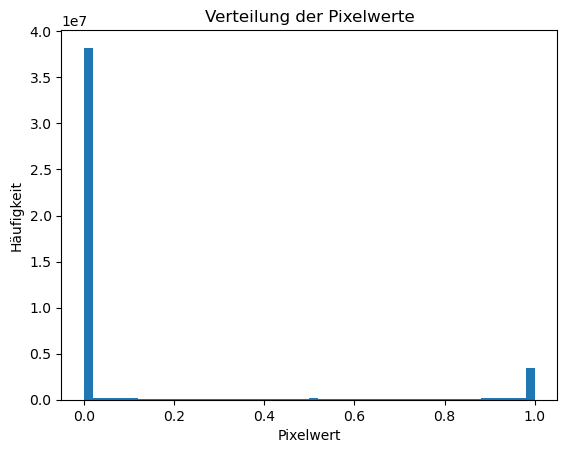

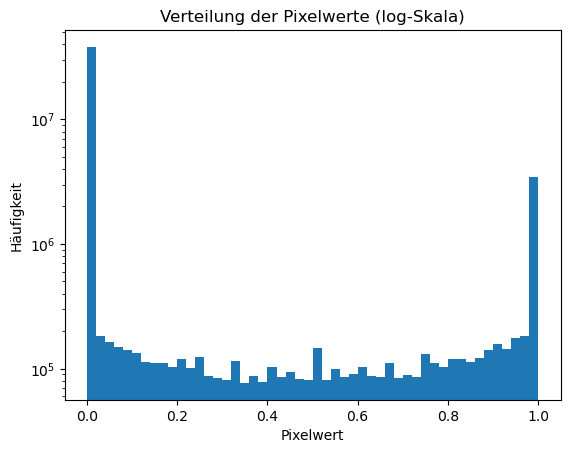

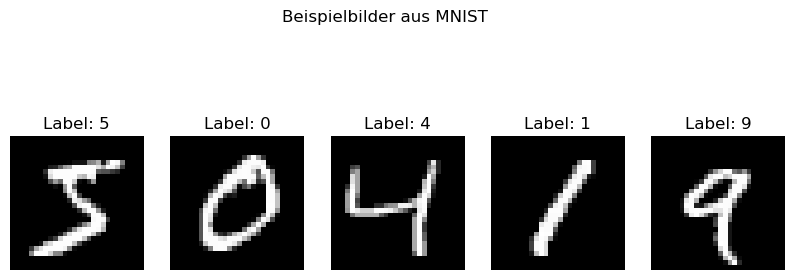

In [4]:
#Verteilung der Pixelwerte anzeigen

plt.figure()

plt.hist(X_train.flatten(), bins=50)

plt.title("Verteilung der Pixelwerte")
plt.xlabel("Pixelwert")
plt.ylabel("Häufigkeit")

plt.savefig("pixelwert_verteilung.png", dpi=300)
plt.show()


# Verteilung der Pixelwerte (logarithmische Skala)

plt.figure()

plt.hist(X_train.flatten(), bins=50, log=True)

plt.title("Verteilung der Pixelwerte (log-Skala)")
plt.xlabel("Pixelwert")
plt.ylabel("Häufigkeit")

plt.savefig("pixelwert_verteilung.png", dpi=300)
plt.show()


# Beispielbilder anzeigen

plt.figure(figsize=(10,4))

for i in range(5):
    plt.subplot(1,5,i+1)
    
    plt.imshow(X_train[i].reshape(28, 28), cmap="gray")  
    
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Beispielbilder aus MNIST")

plt.savefig("figures/mnist_beispielbilder.png", dpi=300)
plt.show()

# 2. Datenvorbereitung

# 2.1 Train-Test.Split

In [5]:
# --- Train-Test-Split überprüfen ---

print("Trainingsdaten:", X_train.shape)
print("Testdaten:", X_test.shape)

print("Trainingslabels:", y_train.shape)
print("Testlabels:", y_test.shape)

Trainingsdaten: (60000, 784)
Testdaten: (10000, 784)
Trainingslabels: (60000,)
Testlabels: (10000,)


# 3. Modelle

In diesem Abschnitt werden drei verschiedene Klassifizierungsmodelle implementiert und auf den MNIST-Datensatz angewendet. 
Das Ziel besteht darin, die Leistung der einzelnen Modelle zu vergleichen und anschließend ein Ensemble-Modell zu erstellen.

Die folgenden Modelle werden untersucht:
- Entscheidungsbaum
- Logistische Regression
- k-nächste Nachbarn (kNN)

## 3.1 Entscheidungsbaum

Das Entscheidungsbaum-Modell wurde mithilfe von optimierten Hyperparametern trainiert und auf dem Testdatensatz ausgewertet.

Accuracy Test: 0.8891


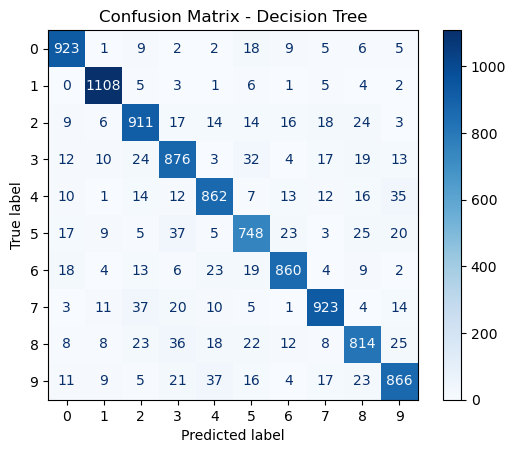

              precision    recall  f1-score   support

           0      0.913     0.942     0.927       980
           1      0.949     0.976     0.963      1135
           2      0.871     0.883     0.877      1032
           3      0.850     0.867     0.859      1010
           4      0.884     0.878     0.881       982
           5      0.843     0.839     0.841       892
           6      0.912     0.898     0.905       958
           7      0.912     0.898     0.905      1028
           8      0.862     0.836     0.849       974
           9      0.879     0.858     0.869      1009

    accuracy                          0.889     10000
   macro avg      0.888     0.887     0.887     10000
weighted avg      0.889     0.889     0.889     10000



In [9]:
# Beste Parameter übernehmen

best_params = {
    'min_samples_split': 2,
    'min_samples_leaf': 2,
    'max_features': None,
    'max_depth': 15,
    'criterion': 'entropy',
    'ccp_alpha': 0.0001
}

# Modell definieren
opt_tree = DecisionTreeClassifier(**best_params, random_state=42)

# Training
opt_tree.fit(X_train, y_train)

# Vorhersagen (Standardisiert)
y_pred_tree = opt_tree.predict(X_test)

# Accuracy 
accuracy_opt = accuracy_score(y_test, y_pred_tree)
print("Accuracy Test:", round(accuracy_opt, 4))

# Probabilities (für Ensemble)
y_prob_tree = opt_tree.predict_proba(X_test)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_tree)

ConfusionMatrixDisplay(cm).plot(cmap="Blues")

plt.title("Confusion Matrix - Decision Tree")

plt.savefig("confusion_matrix_tree.png", bbox_inches="tight")

plt.show()

# Classification Report
print(classification_report(y_test, y_pred_tree, digits=3))

## 3.2 k-Nearest Neighbors

kNN Accuracy: 0.9705


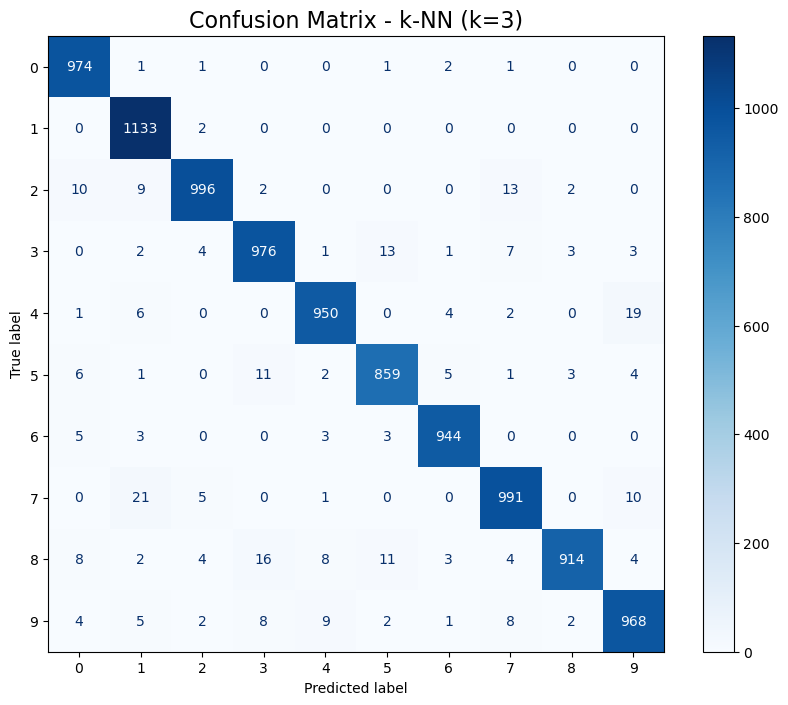

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.96      1.00      0.98      1135
           2       0.98      0.97      0.97      1032
           3       0.96      0.97      0.96      1010
           4       0.98      0.97      0.97       982
           5       0.97      0.96      0.96       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.99      0.94      0.96       974
           9       0.96      0.96      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



In [10]:
# Flatten der Bilder
X_train_flat = X_train.reshape(len(X_train), -1)
X_test_flat = X_test.reshape(len(X_test), -1)

# Modell definieren
# Bester Wert für k (aus Cross-Validation)
bestes_k = 3

knn_final = KNeighborsClassifier(n_neighbors=bestes_k, n_jobs=-1)

# Training
knn_final.fit(X_train_flat, y_train)

# Vorhersagen (Standardisiert)
y_pred_knn = knn_final.predict(X_test_flat)

# Accuracy
acc_knn = accuracy_score(y_test, y_pred_knn)
print("kNN Accuracy:", round(acc_knn, 4))

# Probabilities (für Ensemble)
y_prob_knn = knn_final.predict_proba(X_test_flat)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_knn)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(ax=ax, cmap='Blues', values_format='d')

plt.title("Confusion Matrix - k-NN (k=3)", fontsize=16)

plt.savefig("confusion_matrix_knn.png", bbox_inches="tight")

plt.show()

# Classification Report
report = classification_report(y_test, y_pred_knn, target_names=[str(i) for i in range(10)])
print(report)

## 3.3 Logistische Regression

LogReg Accuracy: 0.9271


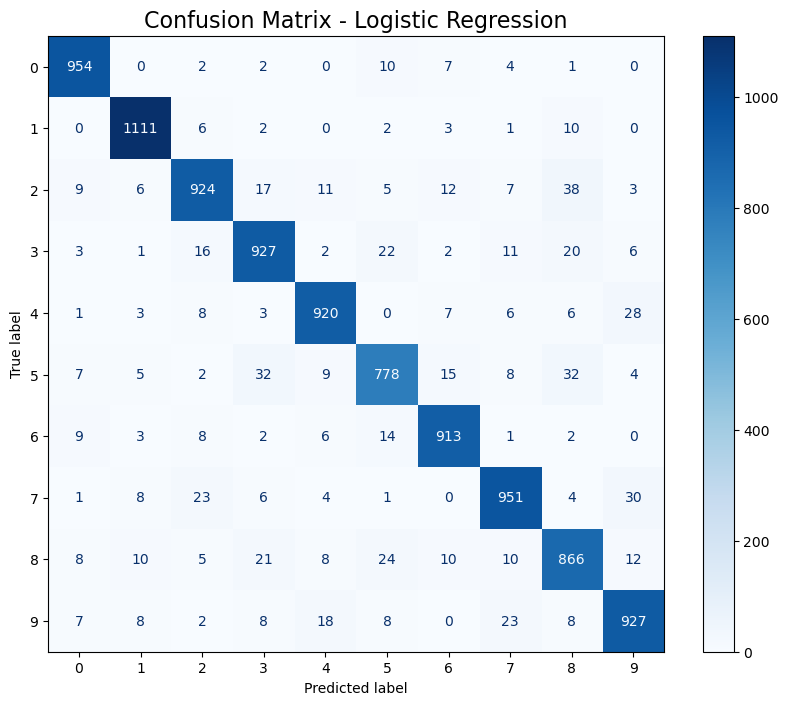

Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.97      0.96       980
           1       0.96      0.98      0.97      1135
           2       0.93      0.90      0.91      1032
           3       0.91      0.92      0.91      1010
           4       0.94      0.94      0.94       982
           5       0.90      0.87      0.89       892
           6       0.94      0.95      0.95       958
           7       0.93      0.93      0.93      1028
           8       0.88      0.89      0.88       974
           9       0.92      0.92      0.92      1009

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



In [7]:
scaler = StandardScaler()
X_train_clean_norm = scaler.fit_transform(X_train.reshape(-1, (28*28)).astype(np.float32))
X_test_clean_norm = scaler.transform(X_test.reshape(-1, (28*28)).astype(np.float32))

# Beste Parameter übernehmen
best_params = {
    'C': 0.1,
    'max_iter': 3000,
    'penalty': 'l2',
    'tol': 0.0001
}

# Modell definieren
log_model = LogisticRegression(**best_params, random_state=42)

# Training
log_model.fit(X_train_clean_norm, y_train)

# Vorhersagen (Standardisiert)
y_pred_log = log_model.predict(X_test_clean_norm)

# Accuracy
acc_log = accuracy_score(y_test, y_pred_log)
print("LogReg Accuracy:", round(acc_log, 4))

# Probabilities (für Ensemble)
y_prob_log = log_model.predict_proba(X_test_clean_norm)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred_log)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(ax=ax, cmap='Blues', values_format='d')

plt.title("Confusion Matrix - Logistic Regression", fontsize=16)

plt.savefig("confusion_matrix_logreg.png", bbox_inches="tight")

plt.show()

# Classification Report
print("Classification Report:\n", classification_report(y_test, y_pred_log))

# 3.4 Vergleich aller Einzelmodelle

In [11]:
# Vergleich aller Einzelmodelle

vergleich_df = pd.DataFrame({
    "Modell": ["Decision Tree", "kNN", "Logistische Regression"],
    "Accuracy": [accuracy_opt, acc_knn, acc_log]
})

vergleich_df = vergleich_df.sort_values(by="Accuracy", ascending=False)

print("\n=== Modellvergleich als Tabelle ===")
print(vergleich_df)


=== Modellvergleich als Tabelle ===
                   Modell  Accuracy
1                     kNN    0.9705
2  Logistische Regression    0.9271
0           Decision Tree    0.8891


# 4. Ensemble

## Ensemble mit Training auf Testdaten
### verworfen

Dieser Ansatz ist methodisch falsch, da die Modelle auf den Testdaten trainiert wurden.
Dies führt zu Overfitting und unrealistisch hohen Genauigkeiten.
Die Testdaten dürfen ausschließlich zur Evaluation verwendet werden.

In [12]:
# --- VERWORFEN: Training auf Testdaten ---

print("Dieser Ansatz wurde als methodisch falsch erkannt und wird nicht ausgeführt.")

if False:
    # Training auf Testdaten
    opt_tree.fit(X_test, y_test)
    knn_final.fit(X_test_flat, y_test)
    log_model.fit(x_test_clean_norm, y_test)

    # Vorhersagen
    y_pred_tree = opt_tree.predict(X_test)
    y_pred_knn = knn_final.predict(X_test_flat)
    y_pred_log = log_model.predict(x_test_clean_norm)

    # Ensemble
    y_pred_ensemble = []

    for i in range(len(y_pred_tree)):
        votes = [y_pred_tree[i], y_pred_knn[i], y_pred_log[i]]
        counts = np.bincount(votes)
        y_pred_ensemble.append(np.argmax(counts))

    y_pred_ensemble = np.array(y_pred_ensemble)

    acc_ensemble = accuracy_score(y_test, y_pred_ensemble)

    print("Falsches Ensemble Accuracy:", acc_ensemble)

Dieser Ansatz wurde als methodisch falsch erkannt und wird nicht ausgeführt.


## 4.1 Hard Voting

Beim Hard Voting werden die Vorhersagen mehrerer Modelle kombiniert. 
Die finale Klasse wird durch Mehrheitsentscheidung bestimmt.

für jede Beobachtung werden die Vorhersagen der drei Modelle 
(Entscheidungsbaum, k-Nearest Neighbors und logistische Regression) 
verglichen. Die Klasse, die am häufigsten vorhergesagt wird, wird als finale 
Vorhersage gewählt.

Dieses Verfahren nutzt die Stärken der einzelnen Modelle und kann die 
Gesamtgenauigkeit verbessern.

### verworfen 

Dieser Ansatz funktioniert zwar korrekt, ist jedoch ineffizient und unnötig komplex.
Bibliotheken wie NumPy bieten deutlich effizientere Lösungen (z.B. np.bincount).
Daher wurde dieser Ansatz durch eine optimierte Implementierung ersetzt.

In [13]:
# --- VERWORFEN: Manuelles Hard Voting ---

print("Dieser Ansatz wurde als ineffizient und unnötig komplex erkannt und wird nicht ausgeführt.")

if False:
    y_pred_slow = []

    for i in range(len(y_pred_tree)):
        counter = {}

        for pred in [y_pred_tree[i], y_pred_knn[i], y_pred_log[i]]:
            if pred in counter:
                counter[pred] += 1
            else:
                counter[pred] = 1

        # manuelles Maximum suchen
        max_vote = -1
        best_class = None

        for key in counter:
            if counter[key] > max_vote:
                max_vote = counter[key]
                best_class = key

        y_pred_slow.append(best_class)

    y_pred_slow = np.array(y_pred_slow)

    acc_slow = accuracy_score(y_test, y_pred_slow)

    print("Langsames Hard Voting:", acc_slow)

Dieser Ansatz wurde als ineffizient und unnötig komplex erkannt und wird nicht ausgeführt.


In [15]:
# Hard Voting Ensemble

# Hard Voting Funktion
def hard_voting(pred1, pred2, pred3):
    ensemble_pred = []
    
    for i in range(len(pred1)):
        votes = [pred1[i], pred2[i], pred3[i]]
        
        # Mehrheitsentscheidung
        counts = np.bincount(votes)
        final_pred = np.argmax(counts)
        
        ensemble_pred.append(final_pred)
    
    return np.array(ensemble_pred)

# Ensemble Vorhersagen
y_pred_ensemble = hard_voting(y_pred_tree, y_pred_knn, y_pred_log)

# Accuracy
acc_ensemble = accuracy_score(y_test, y_pred_ensemble)

print("Ensemble Accuracy (Hard Voting):", round(acc_ensemble, 4))

# Vergleich
print("\n--- Vergleich der Modelle ---")
print("Decision Tree:", round(accuracy_opt, 4))
print("kNN:", round(acc_knn, 4))
print("LogReg:", round(acc_log, 4))
print("Ensemble (Hard Voting):", round(acc_ensemble, 4))
print("\n=== Modellvergleich ===")

Ensemble Accuracy (Hard Voting): 0.9588

--- Vergleich der Modelle ---
Decision Tree: 0.8891
kNN: 0.9705
LogReg: 0.9271
Ensemble (Hard Voting): 0.9588

=== Modellvergleich ===


## 4.2 Soft Voting

Für das Ensemble wurde zusätzlich ein Soft Voting Ansatz implementiert.

Dabei wurden die Wahrscheinlichkeiten der einzelnen Modelle gemittelt, um eine finale Vorhersage zu treffen. Im Gegensatz zum Hard Voting berücksichtigt diese Methode die Sicherheit der einzelnen Modelle.

In [16]:
# Soft Voting Ensemble

# Soft Voting (Mittelwert der Wahrscheinlichkeiten)
y_prob_ensemble = (y_prob_tree + y_prob_knn + y_prob_log) / 3

# Finale Vorhersagen
y_pred_soft = np.argmax(y_prob_ensemble, axis=1)

# Accuracy
acc_soft = accuracy_score(y_test, y_pred_soft)

print("Ensemble Accuracy (Soft Voting):", round(acc_soft, 4))

# Vergleich
print("\n=== Modellvergleich ===")
print("Decision Tree:", round(accuracy_opt, 4))
print("kNN:", round(acc_knn, 4))
print("LogReg:", round(acc_log, 4))
print("Hard Voting:", round(acc_ensemble, 4))
print("Soft Voting:", round(acc_soft, 4))

Ensemble Accuracy (Soft Voting): 0.9654

=== Modellvergleich ===
Decision Tree: 0.8891
kNN: 0.9705
LogReg: 0.9271
Hard Voting: 0.9588
Soft Voting: 0.9654


## 4.3 VotingClassifier

### Hard VotingClassifier

In [17]:
# gleiche Daten für alle Modelle!
X_train_ens = X_train.reshape(len(X_train), -1)
X_test_ens = X_test.reshape(len(X_test), -1)

# VotingClassifier definieren (Hard Voting)
voting_clf_hard = VotingClassifier(
    estimators=[
        ('tree', opt_tree),
        ('knn', knn_final),
        ('logreg', log_model)
    ],
    voting='hard'
)

# Modell trainieren
voting_clf_hard.fit(X_train, y_train)

# Vorhersagen
y_pred_voting_hard = voting_clf_hard.predict(X_test)

# Accuracy
acc_voting_hard = accuracy_score(y_test, y_pred_voting_hard)

print("VotingClassifier (Hard):", round(acc_voting_hard, 4))

VotingClassifier (Hard): 0.957


### Soft VotingClassifier

Beim Soft Voting werden die Wahrscheinlichkeiten der Modelle kombiniert. Durch die Gewichtung [1, 3, 1] wird das kNN-Modell stärker berücksichtigt, da es die beste Performance zeigt. Dadurch kann die Gesamtgenauigkeit leicht verbessert werden.

In [18]:
 # gleiche Daten für alle Modelle!
X_train_ens = X_train.reshape(len(X_train), -1)
X_test_ens = X_test.reshape(len(X_test), -1)

# VotingClassifier definieren (Soft Voting)

voting_clf_soft = VotingClassifier(
    estimators=[
        ('tree', opt_tree),
        ('knn', knn_final),
        ('logreg', log_model)
    ],
    voting='soft',
    weights=[1, 3, 1] # kNN wird stärker gewichtet (beste Performance), Tree und LogReg haben geringeren Einfluss
)

# Modell trainieren
voting_clf_soft.fit(X_train, y_train)

# Vorhersagen
y_pred_voting_soft = voting_clf_soft.predict(X_test)

# Accuracy
acc_voting_soft = accuracy_score(y_test, y_pred_voting_soft)

print("VotingClassifier (Soft):", round(acc_voting_soft, 4))

VotingClassifier (Soft): 0.9726


# 5. Evaluation

## 5.1 Vergleich der Modelle

Zusätzlich zu den manuell implementierten Ensemble-Methoden wurde auch der VotingClassifier verwendet.

Die Ergebnisse zeigen, dass der VotingClassifier vergleichbare Leistungen erzielt und die Implementierung vereinfacht.

In [19]:
print("\n=== Gesamtvergleich ===")
print("Decision Tree:", round(accuracy_opt, 4))
print("kNN:", round(acc_knn, 4))
print("LogReg:", round(acc_log, 4))
print("Hard Voting:", round(acc_ensemble, 4))
print("Soft Voting:", round(acc_soft, 4))
print("VotingClassifier Hard:", round(acc_voting_hard, 4))
print("VotingClassifier Soft:", round(acc_voting_soft, 4))


=== Gesamtvergleich ===
Decision Tree: 0.8891
kNN: 0.9705
LogReg: 0.9271
Hard Voting: 0.9588
Soft Voting: 0.9654
VotingClassifier Hard: 0.957
VotingClassifier Soft: 0.9726


## 5.2 Konfusionsmatrix des Ensemble-Modells

Die Konfusionsmatrix basiert auf dem besten Modell, dem VotingClassifier mit Soft Voting. Dieses Modell erzielte die höchste Genauigkeit und zeigt eine sehr gute Klassifikationsleistung über alle Klassen hinweg.

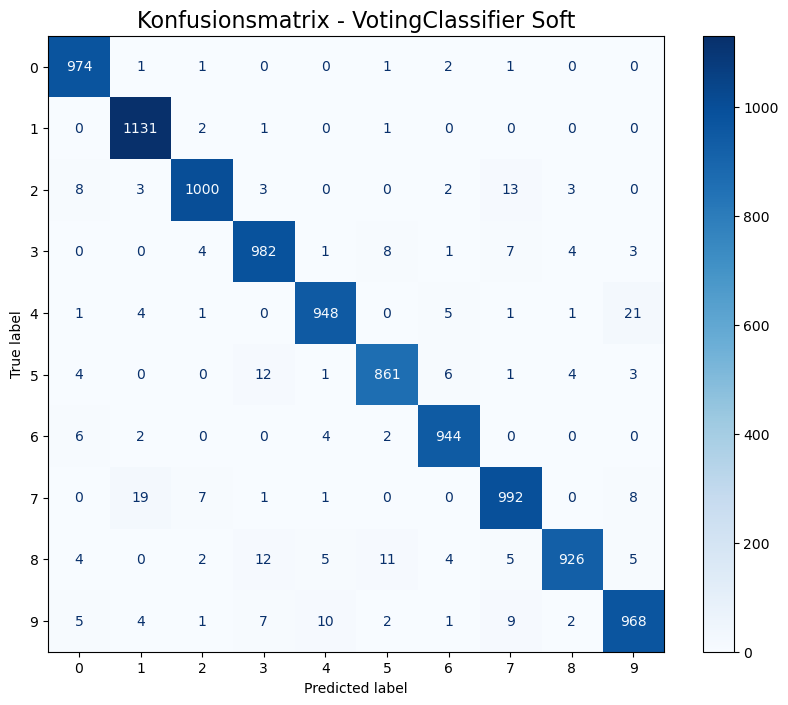

In [20]:
# Konfusionsmatrix für das beste Modell (VotingClassifier Soft)

cm_soft = confusion_matrix(y_test, y_pred_voting_soft)

fig, ax = plt.subplots(figsize=(10, 8))

disp = ConfusionMatrixDisplay(confusion_matrix=cm_soft, display_labels=range(10))
disp.plot(ax=ax, cmap='Blues', values_format='d')

plt.title("Konfusionsmatrix - VotingClassifier Soft", fontsize=16)

plt.savefig("confusion_matrix_best_model.png", bbox_inches="tight")

plt.show()

## 5.3 Grafischer Vergleich der Modelle

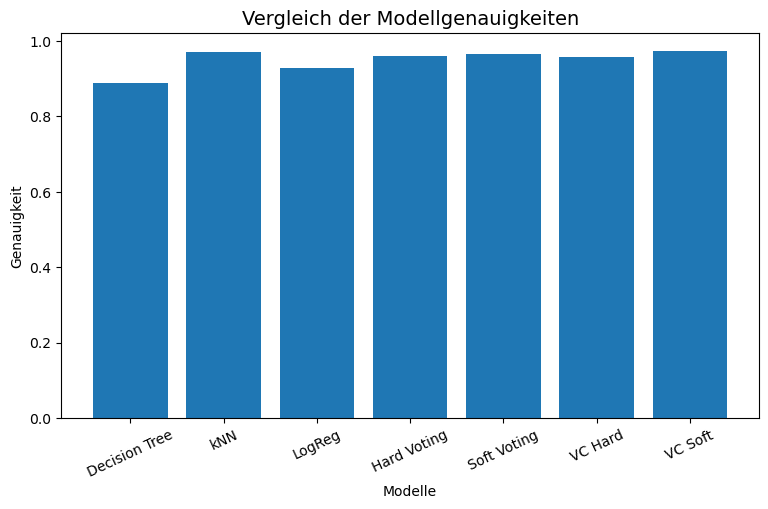

In [21]:
import matplotlib.pyplot as plt

models = [
    "Decision Tree", "kNN", "LogReg",
    "Hard Voting", "Soft Voting",
    "VC Hard", "VC Soft"
]

accuracies = [
    accuracy_opt, acc_knn, acc_log,
    acc_ensemble, acc_soft,
    acc_voting_hard, acc_voting_soft
]

plt.figure(figsize=(9, 5))
plt.bar(models, accuracies)

plt.title("Vergleich der Modellgenauigkeiten", fontsize=14)
plt.xlabel("Modelle")
plt.ylabel("Genauigkeit")

plt.xticks(rotation=25)

plt.savefig("modellvergleich.png", bbox_inches="tight")

plt.show()